# W6 Tutorial — Environmental Statistics
**EN524R / CE801V · Week 6 · October 22, 2026**

**Teaching question:** How is hourly PM₂.₅ related to wind speed at Zhongli, and how uncertain are our descriptive statistics?

**Workflow:** Describe → Estimate → Associate → Diagnose → Interpret → Commit.

Continue the W2–W5 GitHub project. Prefer the W5 output `data/processed/w5_qaqc_hourly.csv`; otherwise reproduce the W5 negative-value screening from the W2 teaching CSV. Never modify the original data.

**Caution:** This is a **seven-day teaching sample**. Simple hourly bootstrap assumes independent observations; day-block resampling is included as a comparison, not as definitive inference. Correlation does not imply causation.

## Step 0 — Setup and locate the project
Save as `notebooks/05_statistics.ipynb` inside your **existing repository**. Change the variable names and QA/QC assumptions for your own PBL.

In [3]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

OUTCOME = 'PM2.5_qc'
PREDICTOR = 'WS'
N_BOOT = 4000
SEED = 42
candidates = [Path.cwd(), *Path.cwd().parents, Path('/content/EN524R_W2_GitHub_Demo')]
PROJECT_ROOT = next((p for p in candidates if (p/'data/sample/zhongli_aq_2025.csv').is_file()), None)
if PROJECT_ROOT is None:
    raise FileNotFoundError('Cannot find data/sample/zhongli_aq_2025.csv. Open inside the existing project or use the W6 starter ZIP.')
W5_FILE = PROJECT_ROOT/'data/processed/w5_qaqc_hourly.csv'
SAMPLE_FILE = PROJECT_ROOT/'data/sample/zhongli_aq_2025.csv'
INPUT_FILE = W5_FILE if W5_FILE.is_file() else SAMPLE_FILE
FIGURES_DIR = PROJECT_ROOT/'figures'
PROCESSED_DIR = PROJECT_ROOT/'data/processed'
FIGURES_DIR.mkdir(exist_ok=True, parents=True)
PROCESSED_DIR.mkdir(exist_ok=True, parents=True)
print('Project:', PROJECT_ROOT)
print('Input:', INPUT_FILE.relative_to(PROJECT_ROOT))

Project: /Users/sheng-po/Library/CloudStorage/Dropbox/20231204_中原環工/05_課程/115-1_環境數據分析/01_PPT/materials_for_W6/EN524R_W2_GitHub_Demo
Input: data/processed/w5_qaqc_hourly.csv


## Step 1 — Load, inspect, and verify QA/QC
Use screened PM₂.₅. Exclude the invalid negative codes **from the QC variable**, but **retain 185 µg/m³** for the primary analysis because it has not been confirmed erroneous.

In [6]:
raw = pd.read_csv(INPUT_FILE)
assert {'datetime', PREDICTOR}.issubset(raw.columns), 'Missing datetime or predictor column.'
x = raw.copy()
x['datetime'] = pd.to_datetime(x['datetime'], errors='coerce')
if OUTCOME not in x.columns:
    assert 'PM2.5' in x.columns
    x['PM2.5'] = pd.to_numeric(x['PM2.5'], errors='coerce')
    x[OUTCOME] = x['PM2.5'].where(x['PM2.5'] >= 0)
    print('W5 file absent: reproduced W5 negative-value screening from the W2 sample.')
else:
    x[OUTCOME] = pd.to_numeric(x[OUTCOME], errors='coerce')
x[PREDICTOR] = pd.to_numeric(x[PREDICTOR], errors='coerce')
x = x.sort_values('datetime').reset_index(drop=True)
assert x['datetime'].notna().all(), 'Invalid timestamp found.'
assert not x['datetime'].duplicated().any(), 'Duplicate timestamps in teaching sample.'
print('Rows:', len(x), '| Valid screened values:', x[OUTCOME].count())
display(x[['datetime', OUTCOME, PREDICTOR]].head())

Rows: 168 | Valid screened values: 165


,datetime,PM2.5_qc,WS
0,2025-01-01 00:00:00,14.3,1.6
1,2025-01-01 01:00:00,13.3,3.6
2,2025-01-01 02:00:00,9.1,1.2
3,2025-01-01 03:00:00,14.0,1.0
4,2025-01-01 04:00:00,13.9,1.4


## Step 2 — Describe: center, spread, and shape (slides 65–66)
The mean alone cannot describe skewness or extreme values. Show mean, median, IQR, SD and a histogram.

,Metric,Value
0,N valid,165.000
1,Mean,25.448
2,Median,23.900
3,SD,14.901
4,Q1,19.200
5,Q3,31.000
6,IQR,11.800
7,Min,5.300
8,Max,185.000


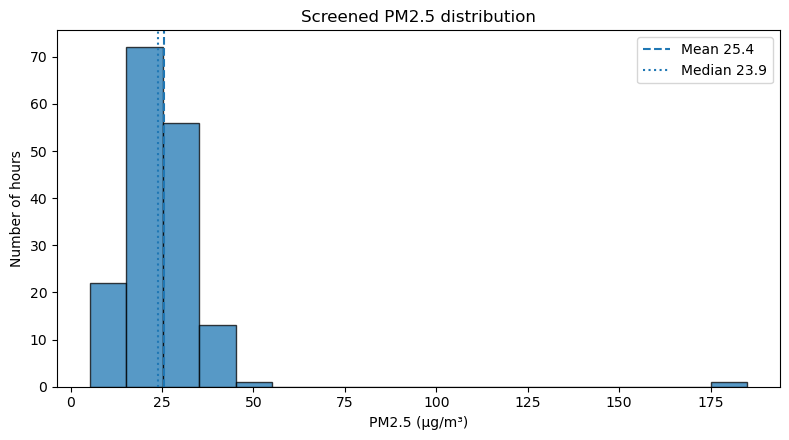

In [9]:
vals = x[OUTCOME].dropna()
summary = pd.DataFrame({'Metric':['N valid','Mean','Median','SD','Q1','Q3','IQR','Min','Max'],
    'Value':[len(vals),vals.mean(),vals.median(),vals.std(ddof=1),vals.quantile(.25),vals.quantile(.75),vals.quantile(.75)-vals.quantile(.25),vals.min(),vals.max()]})
display(summary.round(3))
fig, ax = plt.subplots(figsize=(8,4.5))
ax.hist(vals, bins=18, edgecolor='black', alpha=.75)
ax.axvline(vals.mean(), linestyle='--', label=f'Mean {vals.mean():.1f}')
ax.axvline(vals.median(), linestyle=':', label=f'Median {vals.median():.1f}')
ax.set(xlabel='PM2.5 (µg/m³)', ylabel='Number of hours', title='Screened PM2.5 distribution')
ax.legend(); fig.tight_layout()
fig.savefig(FIGURES_DIR/'w6_pm25_histogram.png', dpi=160); plt.show()

## Step 3 — Estimate: IID bootstrap (slides 67–68)
Draw 4,000 bootstrap samples of **individual hours**. This is the method shown in the slide. It assumes hourly observations are exchangeable/independent for uncertainty purposes, which may be unrealistic. The percentile interval is **not** a 95% probability statement about a fixed population parameter.

Mean: 25.448 | IID bootstrap 95% interval: [23.496 28.051]


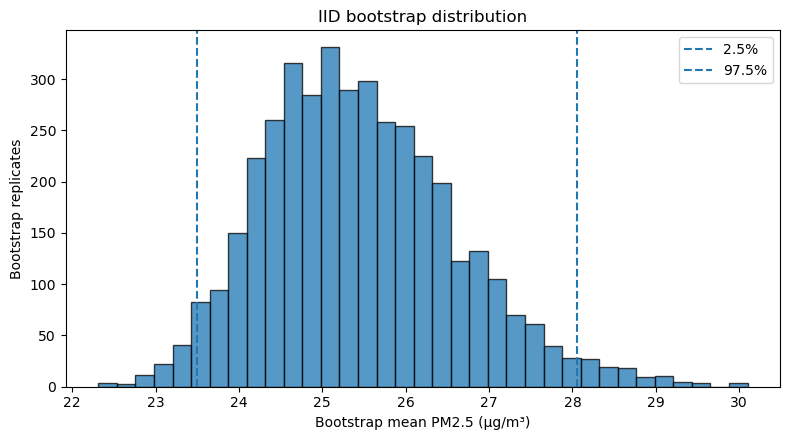

In [12]:
rng = np.random.default_rng(SEED)
array = vals.to_numpy()
boot_iid = np.array([rng.choice(array,len(array),replace=True).mean() for _ in range(N_BOOT)])
ci_iid = np.quantile(boot_iid,[.025,.975])
print('Mean:',round(array.mean(),3),'| IID bootstrap 95% interval:',np.round(ci_iid,3))
fig,ax=plt.subplots(figsize=(8,4.5))
ax.hist(boot_iid,bins=35,edgecolor='black',alpha=.75)
ax.axvline(ci_iid[0],linestyle='--',label='2.5%')
ax.axvline(ci_iid[1],linestyle='--',label='97.5%')
ax.set(xlabel='Bootstrap mean PM2.5 (µg/m³)',ylabel='Bootstrap replicates',title='IID bootstrap distribution')
ax.legend();fig.tight_layout()
fig.savefig(FIGURES_DIR/'w6_bootstrap_iid.png',dpi=160);plt.show()

## Step 4 — Diagnose temporal dependence (slide 71)
Neighboring hourly observations are often correlated. Plot the time series and calculate lag-1 autocorrelation.

Lag-1 autocorrelation: 0.273


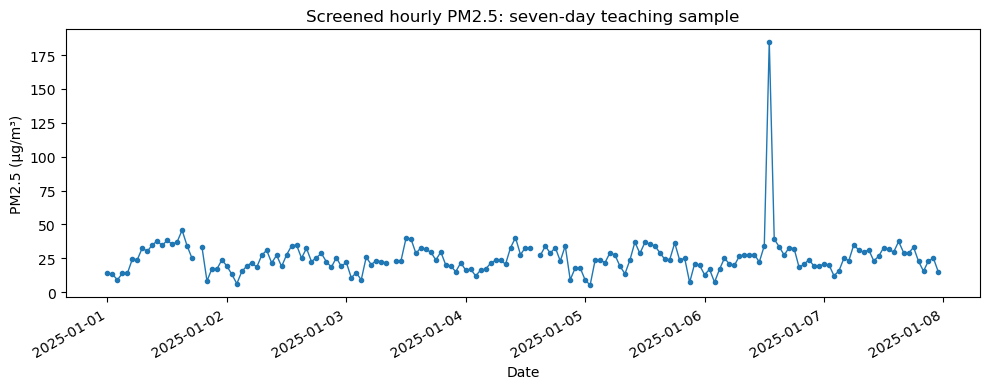

In [15]:
lag1 = x.set_index('datetime')[OUTCOME].autocorr(lag=1)
print('Lag-1 autocorrelation:',round(lag1,3))
fig,ax=plt.subplots(figsize=(10,4))
ax.plot(x['datetime'],x[OUTCOME],marker='.',linewidth=1)
ax.set(xlabel='Date',ylabel='PM2.5 (µg/m³)',title='Screened hourly PM2.5: seven-day teaching sample')
fig.autofmt_xdate();fig.tight_layout()
fig.savefig(FIGURES_DIR/'w6_pm25_timeseries.png',dpi=160);plt.show()

## Step 5 — Day-block bootstrap (additional teaching comparison)
Resample **whole calendar days** rather than individual hours, preserving within-day structure. With only seven days this is an unstable illustration, **not a definitive confidence interval**. It is **not guaranteed to be wider** than the IID interval, and between-day dependence may remain.

In [18]:
x['day']=x['datetime'].dt.normalize()
blocks=[g[OUTCOME].dropna().to_numpy() for _,g in x.groupby('day')]
blocks=[b for b in blocks if len(b)>0]
n_days=len(blocks)
assert n_days>=2
rng_block=np.random.default_rng(SEED)
boot_day=np.empty(N_BOOT)
for i in range(N_BOOT):
    selected=rng_block.integers(0,n_days,size=n_days)
    boot_day[i]=np.concatenate([blocks[j] for j in selected]).mean()
ci_day=np.quantile(boot_day,[.025,.975])
uncertainty=pd.DataFrame({'Method':['IID hourly bootstrap','Day-block bootstrap (illustration)'],
 'Mean':[array.mean(),array.mean()], 'Lower_95':[ci_iid[0],ci_day[0]],
 'Upper_95':[ci_iid[1],ci_day[1]],
 'Assumption':['Hourly observations treated as independent','Resample entire days; only 7 days']})
display(uncertainty.round(3))

,Method,Mean,Lower_95,Upper_95,Assumption
0,IID hourly bootstrap,25.448,23.496,28.051,Hourly observations treated as independent
1,Day-block bootstrap (illustration),25.448,23.952,27.425,Resample entire days; only 7 days


## Step 6 — Pearson vs Spearman: PM₂.₅ vs wind speed (slides 69–70)
Use pairwise complete records. Pearson quantifies linear association; Spearman quantifies monotonic rank association. Neither demonstrates a causal mechanism.

,Metric,Value
0,Paired N,165.0000
1,Pearson r,-0.0868
2,Spearman rho,-0.0989


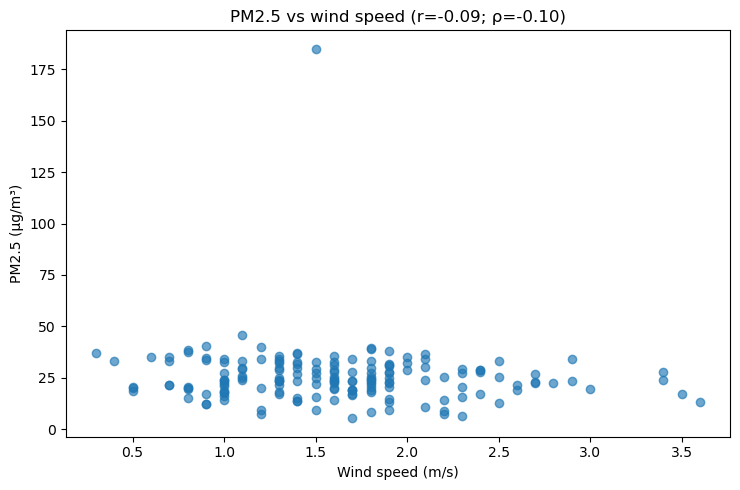

In [21]:
pairs=x[[OUTCOME,PREDICTOR]].dropna()
assert len(pairs)>=3
pearson_r=pairs[OUTCOME].corr(pairs[PREDICTOR],method='pearson')
spearman_rho=pairs[OUTCOME].corr(pairs[PREDICTOR],method='spearman')
association=pd.DataFrame({'Metric':['Paired N','Pearson r','Spearman rho'],
                          'Value':[len(pairs),pearson_r,spearman_rho]})
display(association.round(4))
fig,ax=plt.subplots(figsize=(7.5,5))
ax.scatter(pairs[PREDICTOR],pairs[OUTCOME],alpha=.65)
ax.set(xlabel='Wind speed (m/s)',ylabel='PM2.5 (µg/m³)',
 title=f'PM2.5 vs wind speed (r={pearson_r:.2f}; ρ={spearman_rho:.2f})')
fig.tight_layout();fig.savefig(FIGURES_DIR/'w6_pm25_vs_ws.png',dpi=160);plt.show()

## Step 7 — Sensitivity: retain versus hypothetically exclude 185 µg/m³
The primary analysis **retains** 185. Exclude the exact 185 value **only as a hypothetical comparison**, not as a final QA/QC decision.

In [24]:
flag_185=x[OUTCOME].eq(185)
alt=x.loc[~flag_185,[OUTCOME,PREDICTOR]].dropna()
sensitivity=pd.DataFrame([
 {'Scenario':'Primary: 185 retained','N':len(pairs),'Mean_PM25':vals.mean(),
  'Pearson_r':pearson_r,'Spearman_rho':spearman_rho},
 {'Scenario':'Hypothetical: 185 excluded','N':len(alt),'Mean_PM25':alt[OUTCOME].mean(),
  'Pearson_r':alt[OUTCOME].corr(alt[PREDICTOR],method='pearson'),
  'Spearman_rho':alt[OUTCOME].corr(alt[PREDICTOR],method='spearman')}])
display(sensitivity.round(3))
print('Flagged exact 185 values:',int(flag_185.sum()))

,Scenario,N,Mean_PM25,Pearson_r,Spearman_rho
0,Primary: 185 retained,165,25.448,-0.087,-0.099
1,Hypothetical: 185 excluded,164,24.475,-0.138,-0.098


Flagged exact 185 values: 1


## Step 8 — Interpret with environmental context (slides 72–75)
**Discussion:** Can boundary-layer height, emissions, time of day, or synoptic transport affect both PM₂.₅ and wind speed? What would be needed to test a mechanism?

**Edit this template after running the notebook:**

> In this seven-day teaching sample, hourly PM₂.₅ and wind speed show a [weak/moderate] association (Pearson r = ..., Spearman ρ = ...). The screened mean is ... µg/m³. The IID bootstrap gives an illustrative 95% interval of ...–... µg/m³, but temporal dependence makes this interval potentially misleading. These descriptive results do not establish that wind speed causes PM₂.₅ changes. Longer records and meteorological controls would be needed.

**For your PBL:** Replace the teaching variable, research question, and interpretation with your own data.

## Step 9 — Export outputs (do not overwrite raw data)
Figures go to `figures/`; summary CSVs go to `data/processed/`. Files ignored by Git can be regenerated by running this notebook.

In [28]:
exports={'w6_descriptive_statistics.csv':summary,'w6_uncertainty_comparison.csv':uncertainty,
         'w6_correlations.csv':association,'w6_sensitivity.csv':sensitivity}
for filename,table in exports.items():
    path=PROCESSED_DIR/filename
    table.to_csv(path,index=False)
    print('Saved:',path.relative_to(PROJECT_ROOT))
print('Figures in:',FIGURES_DIR.relative_to(PROJECT_ROOT))

Saved: data/processed/w6_descriptive_statistics.csv
Saved: data/processed/w6_uncertainty_comparison.csv
Saved: data/processed/w6_correlations.csv
Saved: data/processed/w6_sensitivity.csv
Figures in: figures


## Step 10 — README and GitHub checkpoint
Update `README.md` with a **W6 — Environmental Statistics** section: question, input, notebook, descriptive results, uncertainty assumptions, association, interpretation, and limitations.

**Commit Summary:** `Add W6 statistical analysis and uncertainty checks`

**GitHub Desktop:** Changes → Review → Commit to main → Push origin → Verify on GitHub.

**Individual PBL checkpoint (for W9 proposal):** research question, outcome, predictors, data source, QA/QC plan, proposed statistic/figure, and one testable expected pattern.